# Normale verdeling

In de volgende functies gaan we ervan uit dat de parameters mu en sigma van de normale verdeling bekend zijn.

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, probplot

## 1. Gegeven grenswaarden $a$ en $b$, bereken de kans op uitkomst tussen $a$ en $b$

In [62]:
def compute_probabilities(left=None, right=None, mu=0, sigma=1):
    # Kansberekening
    if left is not None and right is not None:
        assert left <= right
        prob = norm.cdf(right, mu, sigma) - norm.cdf(left, mu, sigma)
        print(f"P({left} <= X <= {right}) = {prob:.4f}")
        return prob
    elif left is not None:
        prob = 1 - norm.cdf(left, mu, sigma)
        print(f"P(X >= {left}) = {prob:.4f}")
        return prob
    else:
        prob = norm.cdf(right, mu, sigma)
        print(f"P(X <= {right}) = {prob:.4f}")
        return prob

compute_probabilities(left=0, right=1, mu=0, sigma=1)

P(0 <= X <= 1) = 0.3413


0.3413447460685429

## 2. Gegeven kans $p$, bereken de grenswaarden behorende bij deze kans $p$

In [65]:
def compute_boundary_values(area=0.05, mu=0, sigma=1, tail="left"):
    if tail == "left":
        g = norm.ppf(area, mu, sigma)
        print(f"P(X <= g) = {area} geeft g = {g:.4f}")
        return g
    elif tail == "center":
        g1, g2 = norm.ppf(area/2, mu, sigma), norm.ppf(1-area/2,mu,sigma)
        print(f"P(g1 <= X <= g2) = {area} geeft g1 = {g1:.4f} en g2 = {g2:.4f}")
        return g1, g2
    else:
        g = norm.ppf(1-area, mu, sigma)
        print(f"P(X >= g) = {area} geeft g = {g:.4f}")
        return g

compute_boundary_values(area=0.05, mu=0, sigma=1, tail="right")

P(X >= g) = 0.05 geeft g = 1.6449


1.6448536269514722

## 3. Gegeven een steekproefgemiddelde $\bar{x}$, standaardafwijking $\sigma$ en steekproefgrootte $n$, bereken het betrouwbaarheidsinterval

In [68]:
def compute_confidence_z_interval(data=None, sample_mean=None, n=None, sigma=1, confidence=0.05, tail="center"):
    if data is not None:
        assert isinstance(data, list)
        n = len(data)
        sample_mean = sum(data) / len(data)
    else:
        assert sample_mean is not None and n is not None
    area = 1 - confidence
    std_error = sigma / np.sqrt(n)

    text = f"\\SI{{{int(100 * area)}}}{{\\percent}}-betrouwbaarheidsinterval voor het gemiddelde $\\mu$ "
    # Kansberekening
    if tail == "left":
        g = norm.ppf(confidence, sample_mean, std_error)
        print(text + f"(linkszijdig): $[{g:.4f}, \\infty)$")
        return g
    elif tail == "center":
        g1 = norm.ppf(confidence / 2, sample_mean, std_error)
        g2 = norm.ppf(1 - confidence / 2, sample_mean, std_error)
        print(text + f"(tweezijdig): $[{g1:.4f}, {g2:.4f}]$")
        return g1, g2
    elif tail == "right":
        g = norm.ppf(1 - confidence, sample_mean, std_error)
        print(text + f"(rechtszijdig): $(-\\infty, {g:.4f}]$")
        return g

print("Exercise 8.4")
compute_confidence_z_interval(sample_mean=1000, sigma=25, n=10, confidence=0.05)
compute_confidence_z_interval(sample_mean=1000, sigma=25, n=25, confidence=0.05)
compute_confidence_z_interval(sample_mean=1000, sigma=25, n=10, confidence=0.01)
compute_confidence_z_interval(sample_mean=1000, sigma=25, n=25, confidence=0.01)

print("\nExercise 8.11:")
compute_confidence_z_interval(data=[91.6, 87.34, 90.8, 89.65, 91.3], sigma=3, confidence=0.05)

print("\n Exercise 8.29:")
compute_confidence_z_interval(sample_mean=30, sigma=0.5, n=25, confidence=0.05)

print("\n Exercise 8.29:")
compute_confidence_z_interval(sample_mean=30, sigma=0.5, n=25, confidence=0.05)

Exercise 8.4
\SI{95}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[984.5051, 1015.4949]$
\SI{95}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[990.2002, 1009.7998]$
\SI{99}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[979.6363, 1020.3637]$
\SI{99}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[987.1209, 1012.8791]$

Exercise 8.11:
\SI{95}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[87.5084, 92.7676]$

 Exercise 8.29:
\SI{95}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[29.8040, 30.1960]$

 Exercise 8.29:
\SI{95}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[29.8040, 30.1960]$


(29.804003601545993, 30.195996398454007)

## 4. Minimale steekproefgrootte voor een betrouwbaarheidsinterval voor het gemiddelde $\mu$ met afwijking $\pm a$ ($\sigma$ bekend)

In [71]:
def minimum_sample_size(confidence=0.05, std=1, margin=1, whole_interval=False):
    if whole_interval:
        margin = margin / 2
    z = norm.ppf(q=1-confidence/2, loc=0, scale=1)
    n = ((z * std) / (margin)) ** 2
    print(f"Minimale steekproefgrootte $n = \\left(\\frac{{z_{{\\alpha/2}} \\cdot \\sigma}}{{a}}\\right)^2 = {n:.4f}$")

minimum_sample_size(confidence=0.05, std=25, margin=30, whole_interval=True)
minimum_sample_size(confidence=0.01, std=25, margin=30, whole_interval=True)

Minimale steekproefgrootte $n = \left(\frac{z_{\alpha/2} \cdot \sigma}{a}\right)^2 = 10.6707$
Minimale steekproefgrootte $n = \left(\frac{z_{\alpha/2} \cdot \sigma}{a}\right)^2 = 18.4303$


## 5. QQ-normality plots

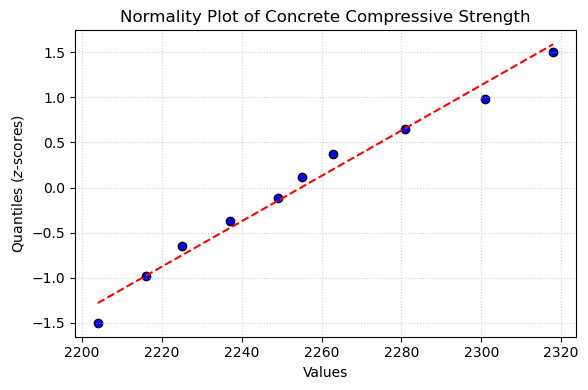

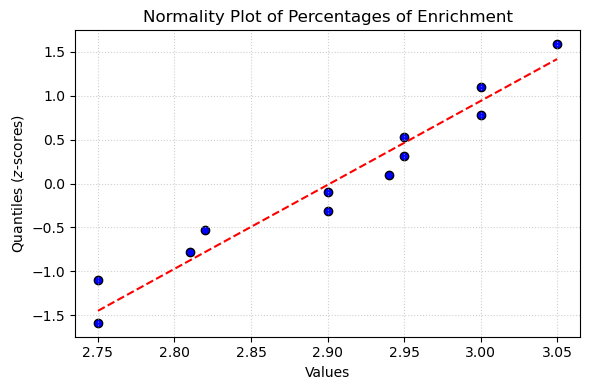

In [76]:
def draw_qq_normality_plot(data, title):
    (z_scores, values), (slope, intercept, _) = probplot(data, dist="norm")

    # Create plot with values on X and z-scores on Y
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(values, z_scores, color="blue", edgecolors="k", label="Data Points")
    
    # Recalculate reference line equation for inverted axes
    fit_line_y = (values - intercept) / slope
    ax.plot(values, fit_line_y, color="red", linestyle="--", label="Fit Line")
    
    ax.set_xlabel("Values")
    ax.set_ylabel("Quantiles ($z$-scores)")
    ax.set_title(title)
    ax.grid(True, linestyle=":", alpha=0.6)
    # ax.legend()
    
    plt.tight_layout()
    plt.show()

data = [2216, 2237, 2249, 2204, 2225, 2301, 2281, 2263, 2318, 2255]
draw_qq_normality_plot(data, "Normality Plot of Concrete Compressive Strength")

data = [2.94, 3.00, 2.90, 2.75, 3.00, 2.95, 2.90, 2.75, 2.95, 2.82, 2.81, 3.05]
draw_qq_normality_plot(data, "Normality Plot of Percentages of Enrichment")

## 6. Bereken $p$-waarde van een $z$-toets